# YZM411 Ödev 1: Renk, Aydınlatma ve Örnekleme

Safa Alp Bilge KILINÇ, Yapay Zeka Mühendisliği, 230212022  
Ders sorumlusu: Öğr. Gör. Melisa Gözet

Defteri Kernel > Restart & Run All ile baştan sona çalıştırıyorum. Fotoğraflar `veri/` klasöründen okunuyor, sonuçlar `ciktilar/` klasörüne yazılıyor.

Giriş dosyaları `veri/` klasöründe, üçünü de kendim çektim:

| Dosya | Koşul | Işık |
|---|---|---|
| `veri/IMG_1671.jpg` | normal | tavan lambası açık |
| `veri/IMG_1673.jpg` | gölge | tavan lambası açık, sahnenin üstünde elimin gölgesi |
| `veri/IMG_1670.jpg` | farklı ışık | tavan lambası kapalı, pencereden gelen akşam gün ışığı |

Üç fotoğraf iPhone 14 Pro Max ile aynı konumdan, 1x ana kamerayla, 13 saniye ve 58 saniye arayla çekildi.

Maskeler, karşılaştırma görselleri ve `sonuc_tablosu.csv` çalıştırınca `ciktilar/` klasörüne yazılıyor.

In [1]:
import os, sys, platform, json
import numpy as np
import cv2
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ExifTags

print("Python    :", platform.python_version())
print("NumPy     :", np.__version__)
print("OpenCV    :", cv2.__version__)
print("pandas    :", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Pillow    :", Image.__version__)

VERI = "veri"
CIKTI = "ciktilar"
os.makedirs(CIKTI, exist_ok=True)
DOSYALAR = {"normal": "IMG_1671.jpg", "gölge": "IMG_1673.jpg", "farklı ışık": "IMG_1670.jpg"}
KOSULLAR = list(DOSYALAR)
# Dosya adlarında Türkçe karakter kullanmıyorum, farklı işletim sistemlerinde ve ZIP içinde bozulabiliyor.
DOSYA_ADI = {"normal": "normal", "gölge": "golge", "farklı ışık": "farkli_isik"}

Python    : 3.13.18
NumPy     : 2.5.3
OpenCV    : 5.0.0
pandas    : 3.0.5
Matplotlib: 3.11.2
Pillow    : 12.3.0


## Parametreler

Üç fotoğrafa da önce aynı `SAHNE` kesiti uygulanıyor (masanın dışındaki çanta ve zemin dışarıda kalsın diye). Aşağıdaki bütün koordinatlar bu kesit üzerinde, `(x, y)` sırasıyla ve piksel cinsindendir. Üç karede de aynı koordinatları kullandım. Aşağıda ölçtüğüm küçük kayma yüzünden bunlar yaklaşık olarak aynı noktaları gösteriyor.

In [2]:
# Sahne kesiti, özgün 4032x3024 fotoğraf üzerinde (x1, y1, x2, y2)
SAHNE = (800, 600, 2500, 2200)

# Adım 4: aynı fiziksel bölgeden üç piksel (x, y)
PIKSELLER = {"sarı kapak": (1000, 1350), "beyaz masa": (1550, 600), "kitap kapağı": (800, 1350)}

# Adım 5: eşik seçmek için sarı nesnenin içinden küçük bir bölge (x1, y1, x2, y2)
NESNE_ROI = (960, 1150, 1060, 1250)
# Raporda "nesnenin içi / dışı" ayrımı için nesneyi saran kutu (x1, y1, x2, y2)
NESNE_KUTU = (895, 900, 1480, 1490)

# Adım 6
PARLAKLIK_B = 40
GAMALAR = [0.5, 2.0]

# Adım 7: yazılı/çizgili bölgeler (x1, y1, x2, y2)
YAZI_KESIT = (500, 1030, 728, 1330)
CIZGI_KESIT = (400, 300, 1000, 700)
OLCEK = 4   # genişlik ve yükseklikte 1/4

## Görüntüleri okuma ve çekim bilgisi (EXIF)

In [3]:
def exif_oku(yol):
    im = Image.open(yol)
    ex = im.getexif()
    d = {ExifTags.TAGS.get(k, k): v for k, v in ex.items()}
    try:
        d.update({ExifTags.TAGS.get(k, k): v for k, v in ex.get_ifd(0x8769).items()})
    except Exception:
        pass
    beyaz = {0: "otomatik", 1: "manuel"}
    poz = {0: "otomatik", 1: "manuel", 2: "otomatik basamaklı"}
    return {
        "model": d.get("Model"),
        "çekim zamanı": d.get("DateTimeOriginal"),
        "pozlama süresi (s)": float(d["ExposureTime"]) if "ExposureTime" in d else None,
        "ISO": d.get("ISOSpeedRatings"),
        "diyafram (f)": float(d["FNumber"]) if "FNumber" in d else None,
        "beyaz dengesi": beyaz.get(d.get("WhiteBalance")),
        "pozlama modu": poz.get(d.get("ExposureMode")),
    }

BGR = {}
for k, ad in DOSYALAR.items():
    yol = os.path.join(VERI, ad)
    tam = cv2.imread(yol, cv2.IMREAD_COLOR)
    assert tam is not None, f"okunamadı: {yol}"
    print(f"{k:12s} özgün boyut: {tam.shape}")
    sx1, sy1, sx2, sy2 = SAHNE
    BGR[k] = tam[sy1:sy2, sx1:sx2].copy()

exif_tablo = pd.DataFrame({k: exif_oku(os.path.join(VERI, a)) for k, a in DOSYALAR.items()}).T
exif_tablo

normal       özgün boyut: (3024, 4032, 3)


gölge        özgün boyut: (3024, 4032, 3)
farklı ışık  özgün boyut: (3024, 4032, 3)


,model,çekim zamanı,pozlama süresi (s),ISO,diyafram (f),beyaz dengesi,pozlama modu
normal,iPhone 14 Pro Max,2026:11:01 17:56:23,0.01,200,1.78,otomatik,otomatik
gölge,iPhone 14 Pro Max,2026:11:01 17:57:21,0.02,250,1.78,otomatik,otomatik
farklı ışık,iPhone 14 Pro Max,2026:11:01 17:56:10,0.058824,3200,1.78,otomatik,otomatik


EXIF'te beyaz dengesi ve pozlama modu üç karede de "otomatik". Telefon bunları her çekimde kendisi ayarlamış, o yüzden fotoğraflar arasındaki farkın tamamını ışığa bağlamıyorum.

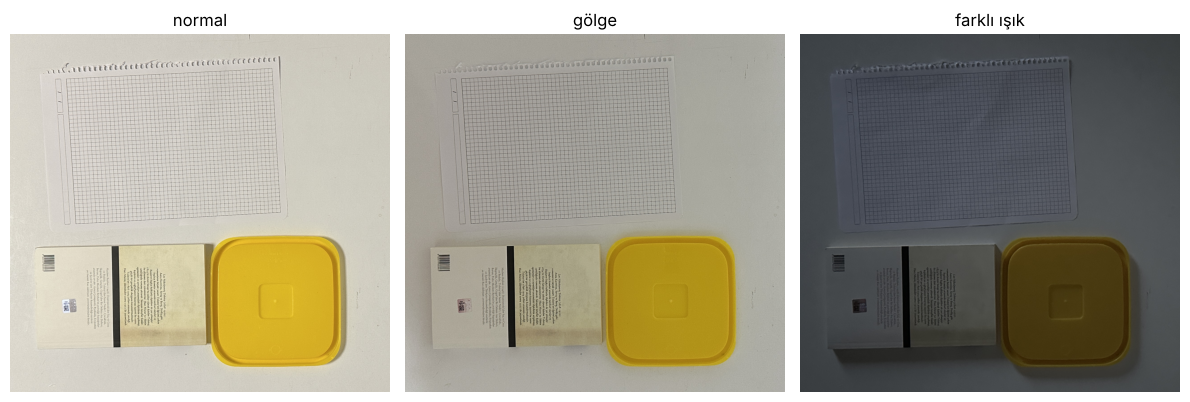

In [4]:
assert len({b.shape for b in BGR.values()}) == 1, "üç fotoğrafın boyutu aynı olmalı"
RGB = {k: cv2.cvtColor(b, cv2.COLOR_BGR2RGB) for k, b in BGR.items()}

fig, ax = plt.subplots(1, 3, figsize=(12, 7))
for a, k in zip(ax, KOSULLAR):
    a.imshow(RGB[k]); a.set_title(k); a.axis("off")
plt.tight_layout(); plt.savefig(f"{CIKTI}/01_ozgun_fotograflar.png", dpi=110); plt.show()

In [5]:
# Telefon kaydı mı? Normal kareye göre kaymayı faz korelasyonuyla ölçüyorum.
gri = {k: cv2.cvtColor(b, cv2.COLOR_BGR2GRAY).astype(np.float32) for k, b in BGR.items()}
for k in ["gölge", "farklı ışık"]:
    (dx, dy), _ = cv2.phaseCorrelate(gri["normal"], gri[k])
    print(f"{k:12s} kayma: dx={dx:+.2f}  dy={dy:+.2f} piksel")
for k in KOSULLAR:
    print(f"{k:12s} kesit ortalaması (üç kanal): {BGR[k].astype(np.float64).mean():.1f}")

gölge        kayma: dx=+0.71  dy=-1.14 piksel
farklı ışık  kayma: dx=-0.12  dy=+0.50 piksel


normal       kesit ortalaması (üç kanal): 193.4
gölge        kesit ortalaması (üç kanal): 152.9
farklı ışık  kesit ortalaması (üç kanal): 71.2


## Adım 4: Görüntünün sayısal yapısı (Hedef 1)

### Tahminim

Gölge karesinde üç noktanın değerleri biraz düşecek ama telefon pozlamayı artırdığı için düşüş küçük olacak, %10'u geçmez diye düşünüyorum. Pencere ışığında üç nokta da çok koyulaşacak ve beyaz masada B kanalı R'den yüksek çıkacak, çünkü akşam gün ışığı tavan lambasından daha mavi.

In [6]:
img = BGR["normal"]
H, W, Cn = img.shape
print("img.shape =", img.shape, "-> H x W x C =", H, "x", W, "x", Cn)
print("dtype     =", img.dtype)
print("aralık    =", int(img.min()), "-", int(img.max()))

# NumPy erişimi img[y, x, kanal]: önce satır (y), sonra sütun (x)
x, y = PIKSELLER["sarı kapak"]
print(f"\nimg[{y}, {x}]      (OpenCV, BGR sırası) =", img[y, x])
print(f"img[{y}, {x}, 0]   (B kanalı)            =", img[y, x, 0])
print(f"img[{y}, {x}, 2]   (R kanalı)            =", img[y, x, 2])
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(f"rgb[{y}, {x}]      (dönüşümden sonra RGB) =", rgb[y, x])
print("ters çevirme ile aynı mı?", np.array_equal(rgb, img[:, :, ::-1]))

img.shape = (1600, 1700, 3) -> H x W x C = 1600 x 1700 x 3
dtype     = uint8
aralık    = 0 - 255

img[1350, 1000]      (OpenCV, BGR sırası) = [ 45 185 224]
img[1350, 1000, 0]   (B kanalı)            = 45
img[1350, 1000, 2]   (R kanalı)            = 224
rgb[1350, 1000]      (dönüşümden sonra RGB) = [224 185  45]
ters çevirme ile aynı mı? True


In [7]:
satirlar = []
for ad, (x, y) in PIKSELLER.items():
    for k in KOSULLAR:
        r, g, b = RGB[k][y, x]
        # tek piksel gürültülü olabileceği için 5x5 komşuluk ortalamasını da yazıyorum
        m = RGB[k][y-2:y+3, x-2:x+3].reshape(-1, 3).mean(0)
        satirlar.append({"nokta": ad, "x": x, "y": y, "koşul": k,
                         "R": int(r), "G": int(g), "B": int(b),
                         "R (5x5 ort.)": round(m[0], 1), "G (5x5 ort.)": round(m[1], 1), "B (5x5 ort.)": round(m[2], 1)})
piksel_tablo = pd.DataFrame(satirlar)
piksel_tablo.to_csv(f"{CIKTI}/adim4_pikseller.csv", index=False, encoding="utf-8-sig")
piksel_tablo

,nokta,x,y,koşul,R,G,B,R (5x5 ort.),G (5x5 ort.),B (5x5 ort.)
0,sarı kapak,1000,1350,normal,224,185,45,219.6,180.9,39.9
1,sarı kapak,1000,1350,gölge,179,148,31,173.8,142.8,25.8
2,sarı kapak,1000,1350,farklı ışık,68,53,14,67.5,52.7,13.7
3,beyaz masa,1550,600,normal,206,204,192,206.2,204.2,192.2
4,beyaz masa,1550,600,gölge,171,171,163,170.9,170.9,162.9
5,beyaz masa,1550,600,farklı ışık,79,83,86,78.4,82.4,85.4
6,kitap kapağı,800,1350,normal,201,188,146,198.5,185.5,143.5
7,kitap kapağı,800,1350,gölge,157,146,114,156.4,145.8,114.0
8,kitap kapağı,800,1350,farklı ışık,59,59,51,60.0,60.0,52.0


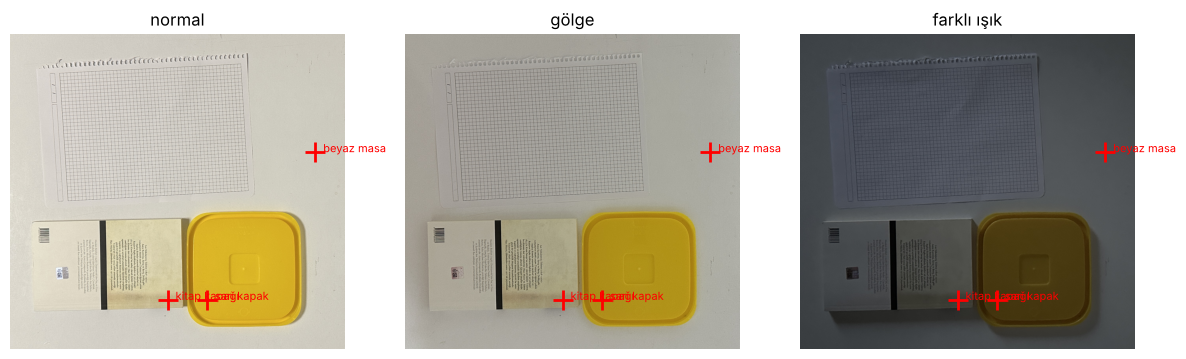

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(12, 7))
for a, k in zip(ax, KOSULLAR):
    a.imshow(RGB[k]); a.set_title(k); a.axis("off")
    for ad, (x, y) in PIKSELLER.items():
        a.plot(x, y, "r+", ms=14, mew=2); a.text(x + 40, y, ad, color="red", fontsize=8)
plt.tight_layout(); plt.savefig(f"{CIKTI}/02_secilen_pikseller.png", dpi=110); plt.show()

## Adım 5: Sabit RGB ve HSV eşikleri (Hedef 2)

Eşikleri yalnızca normal karedeki `NESNE_ROI` bölgesinden seçiyorum: bölgedeki her kanalın %2 ve %98 yüzdeliklerini alıp biraz pay bırakıyorum. Sonra bu değerleri donduruyorum, diğer iki fotoğraf için yeniden ayarlamıyorum.

OpenCV 8 bit HSV: H 0–179, S 0–255, V 0–255.

### Tahminim

Gölgede ışık az değiştiği için iki maske de normaldekine yakın kalacak. Pencere ışığında RGB maskesi neredeyse tamamen kaybolacak çünkü R ve G alt eşiğin altına düşecek; HSV maskesi ton aynı kaldığı için daha çok piksel tutacak ama V alt eşiği yüzünden o da yarıdan fazla küçülecek.

In [9]:
x1, y1, x2, y2 = NESNE_ROI
roi_rgb = RGB["normal"][y1:y2, x1:x2].reshape(-1, 3).astype(float)
roi_hsv = cv2.cvtColor(BGR["normal"], cv2.COLOR_BGR2HSV)[y1:y2, x1:x2].reshape(-1, 3).astype(float)
p_lo, p_hi = np.percentile(roi_rgb, 2, 0), np.percentile(roi_rgb, 98, 0)
h_lo, h_hi = np.percentile(roi_hsv, 2, 0), np.percentile(roi_hsv, 98, 0)
print("ROI RGB %2 :", p_lo.round(), " %98:", p_hi.round())
print("ROI HSV %2 :", h_lo.round(), " %98:", h_hi.round())

ROI RGB %2 : [214. 176.  34.]  %98: [225. 187.  44.]
ROI HSV %2 : [ 23. 205. 214.]  %98: [ 24. 215. 225.]


In [10]:
# Dondurulmuş eşikler (yukarıdaki yüzdeliklerden, payla). Bu değerler bundan sonra değişmiyor.
PAY = 25
RGB_ALT = np.clip(p_lo - PAY, 0, 255).astype(np.uint8)
RGB_UST = np.clip(p_hi + PAY, 0, 255).astype(np.uint8)
HSV_ALT = np.array([max(h_lo[0] - 5, 0), max(h_lo[1] - 40, 0), max(h_lo[2] - 60, 0)]).astype(np.uint8)
HSV_UST = np.array([min(h_hi[0] + 5, 179), 255, 255]).astype(np.uint8)
ESIKLER = {"RGB alt": RGB_ALT.tolist(), "RGB üst": RGB_UST.tolist(),
           "HSV alt": HSV_ALT.tolist(), "HSV üst": HSV_UST.tolist()}
json.dump(ESIKLER, open(f"{CIKTI}/esikler.json", "w", encoding="utf-8"), indent=1, ensure_ascii=False)
ESIKLER

{'RGB alt': [189, 151, 9],
 'RGB üst': [250, 212, 69],
 'HSV alt': [18, 165, 154],
 'HSV üst': [29, 255, 255]}

In [11]:
def rgb_maske(rgb):
    return cv2.inRange(rgb, RGB_ALT, RGB_UST)

def hsv_maske(bgr):
    return cv2.inRange(cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV), HSV_ALT, HSV_UST)

kx1, ky1, kx2, ky2 = NESNE_KUTU
kutu = np.zeros(BGR["normal"].shape[:2], bool); kutu[ky1:ky2, kx1:kx2] = True

MASKE = {}
maske_satir = []
for k in KOSULLAR:
    for tur, m in [("RGB", rgb_maske(RGB[k])), ("HSV", hsv_maske(BGR[k]))]:
        MASKE[(k, tur)] = m
        sec = m > 0
        maske_satir.append({
            "koşul": k, "renk uzayı": tur,
            "seçilen piksel": int(sec.sum()),
            "alan oranı (%)": round(100 * sec.mean(), 2),
            "kutu içi (%)": round(100 * (sec & kutu).sum() / kutu.sum(), 1),
            "kutu dışı piksel": int((sec & ~kutu).sum()),
        })
maske_tablo = pd.DataFrame(maske_satir)
maske_tablo.to_csv(f"{CIKTI}/adim5_maskeler.csv", index=False, encoding="utf-8-sig")
maske_tablo

,koşul,renk uzayı,seçilen piksel,alan oranı (%),kutu içi (%),kutu dışı piksel
0,normal,RGB,297453,10.94,86.2,0
1,normal,HSV,324344,11.92,94.0,4
2,gölge,RGB,8873,0.33,2.6,0
3,gölge,HSV,317839,11.69,92.1,0
4,farklı ışık,RGB,0,0.00,0.0,0
5,farklı ışık,HSV,0,0.00,0.0,0


"Alan oranı" maskenin seçtiği piksel sayısının görüntü alanına oranı, bir doğruluk ölçütü değil. "Kutu içi" nesneyi saran kutunun ne kadarının seçildiğini, "kutu dışı piksel" ise kutunun dışında kalıp eşiği geçen piksel sayısını gösterir. Kutunun köşelerinde kapağa ait olmayan pikseller de var, yani bu sayı nesnenin sınırını vermiyor. Bunları yalnızca maskenin nereye kaydığını görmek için kullanıyorum.

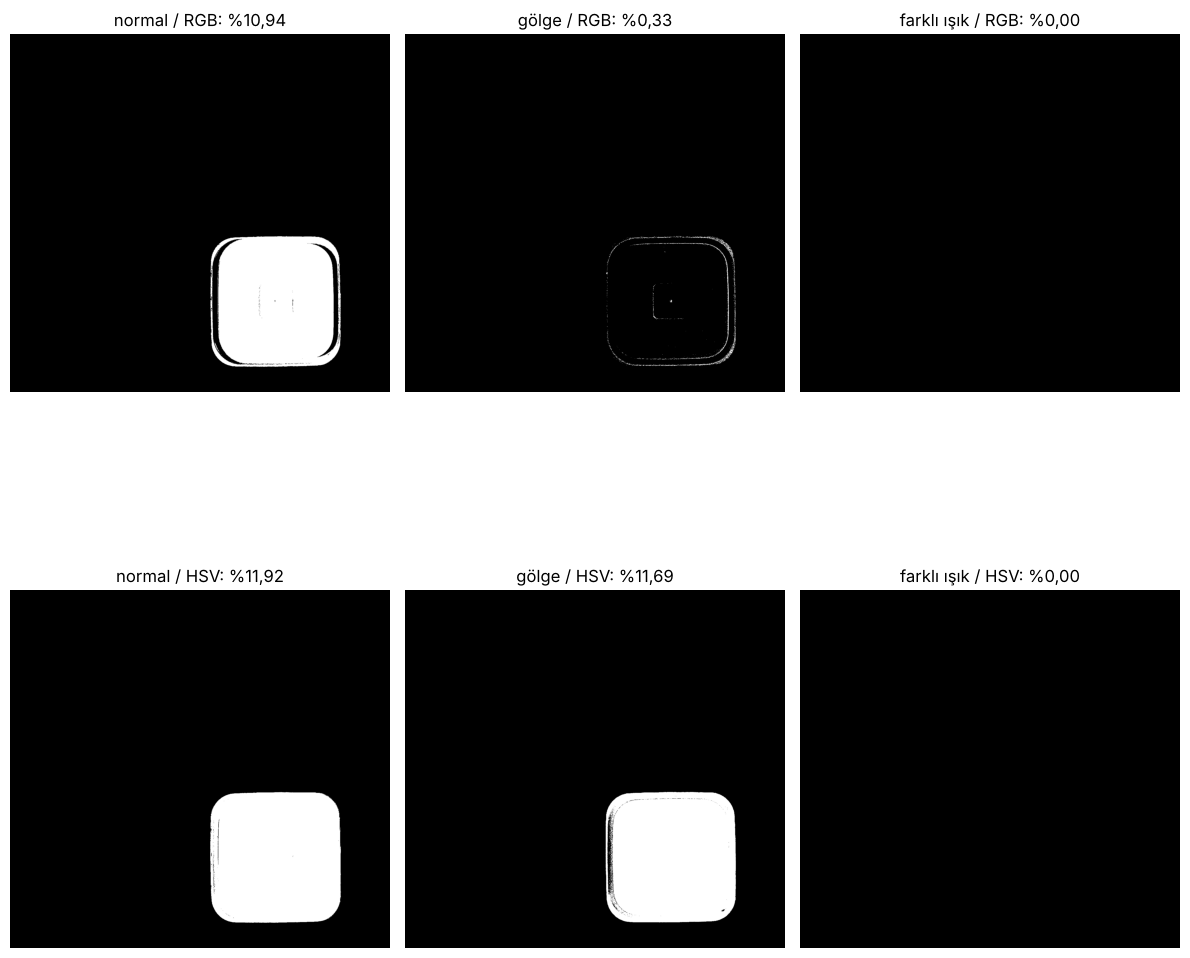

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(12, 13))
for j, k in enumerate(KOSULLAR):
    for i, tur in enumerate(["RGB", "HSV"]):
        m = MASKE[(k, tur)]
        ax[i, j].imshow(m, cmap="gray")
        ax[i, j].set_title(f"{k} / {tur}: %{100 * (m > 0).mean():.2f}".replace(".", ","))
        ax[i, j].axis("off")
        cv2.imwrite(f"{CIKTI}/maske_{DOSYA_ADI[k]}_{tur}.png", m)
plt.tight_layout(); plt.savefig(f"{CIKTI}/03_alti_maske.png", dpi=110); plt.show()

### Kontrol: maskeler neden düştü, sarımsı yüzeyler neden seçilebilir?

Aşağıda aynı bölgelerin HSV medyanlarını üç koşulda yazıyorum. Ardından iki kontrol deneyi yapıyorum. Dondurulmuş eşikler aynen kalıyor, bu deneylerle sadece maskeyi hangi kanalın düşürdüğüne bakıyorum:
1. S alt sınırını 40 gibi gevşek bir değere çekseydim ne seçilirdi?
2. V alt sınırını kaldırsaydım pencere ışığındaki kapak seçilir miydi?

In [13]:
BOLGELER = {"sarı kapak": NESNE_ROI, "kitap kapağı (krem)": (740, 1000, 860, 1380),
            "kitap kapağı (beyaz)": (130, 1300, 300, 1390), "beyaz masa": (1500, 300, 1650, 800)}
hsv_satir = []
for k in KOSULLAR:
    hsv = cv2.cvtColor(BGR[k], cv2.COLOR_BGR2HSV)
    for ad, (x1, y1, x2, y2) in BOLGELER.items():
        r = hsv[y1:y2, x1:x2].reshape(-1, 3)
        hsv_satir.append({"koşul": k, "bölge": ad, "H medyanı": int(np.median(r[:, 0])),
                          "S medyanı": int(np.median(r[:, 1])), "V medyanı": int(np.median(r[:, 2]))})
hsv_bolge = pd.DataFrame(hsv_satir)
hsv_bolge.to_csv(f"{CIKTI}/adim5_hsv_bolgeler.csv", index=False, encoding="utf-8-sig")
hsv_bolge.pivot(index="bölge", columns="koşul", values=["H medyanı", "S medyanı", "V medyanı"])

H medyanı                S medyanı               \
koşul                farklı ışık gölge normal farklı ışık gölge normal   
bölge                                                                    
beyaz masa                   103    30     26          22    12     17   
kitap kapağı (beyaz)         103    21     22          24    29     28   
kitap kapağı (krem)           36    26     25          16    54     55   
sarı kapak                    22    24     24         197   218    210   

                       V medyanı               
koşul                farklı ışık gölge normal  
bölge                                          
beyaz masa                    83   171    206  
kitap kapağı (beyaz)          69   173    224  
kitap kapağı (krem)           78   167    214  
sarı kapak                    71   174    220

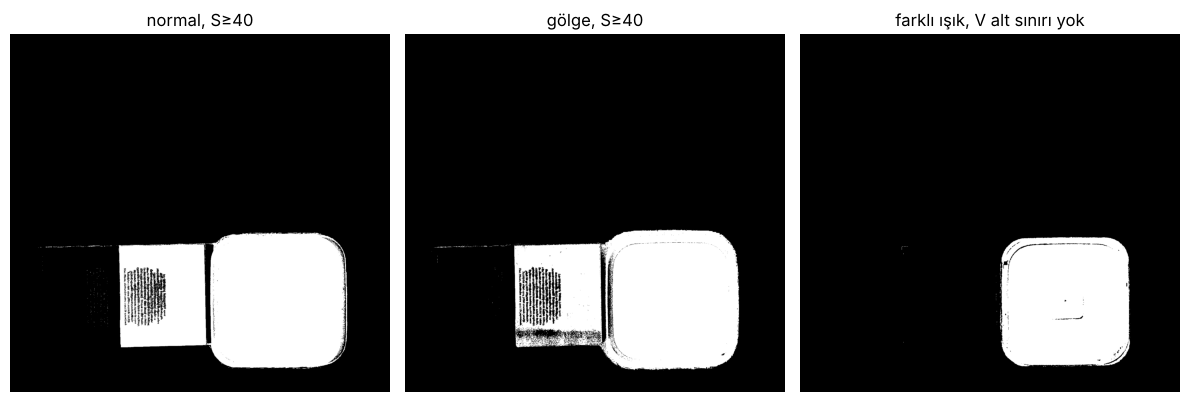

,kontrol,alan oranı (%),kutu içi (%),kutu dışı piksel
0,"normal, S≥40",18.42,96.7,167208
1,"gölge, S≥40",17.90,95.5,157309
2,"farklı ışık, V alt sınırı yok",11.48,90.5,80


In [14]:
GEVSEK_S_ALT = np.array([HSV_ALT[0], 40, HSV_ALT[2]], np.uint8)
V_SIZ_ALT = np.array([HSV_ALT[0], HSV_ALT[1], 0], np.uint8)
kontrol_satir = []
fig, ax = plt.subplots(1, 3, figsize=(12, 4.5))
for j, (baslik, k, alt) in enumerate([("normal, S≥40", "normal", GEVSEK_S_ALT),
                                      ("gölge, S≥40", "gölge", GEVSEK_S_ALT),
                                      ("farklı ışık, V alt sınırı yok", "farklı ışık", V_SIZ_ALT)]):
    m = cv2.inRange(cv2.cvtColor(BGR[k], cv2.COLOR_BGR2HSV), alt, HSV_UST) > 0
    kontrol_satir.append({"kontrol": baslik, "alan oranı (%)": round(100 * m.mean(), 2),
                          "kutu içi (%)": round(100 * (m & kutu).sum() / kutu.sum(), 1),
                          "kutu dışı piksel": int((m & ~kutu).sum())})
    ax[j].imshow(m, cmap="gray"); ax[j].set_title(baslik); ax[j].axis("off")
plt.tight_layout(); plt.savefig(f"{CIKTI}/03b_kontrol_maskeleri.png", dpi=110); plt.show()
kontrol_tablo = pd.DataFrame(kontrol_satir)
kontrol_tablo.to_csv(f"{CIKTI}/adim5_kontrol.csv", index=False, encoding="utf-8-sig")
kontrol_tablo

## Adım 6: Parlaklık kaydırması ve gama (Hedef 3)

İşlemler float üzerinde yapılıyor ve sonuç [0, 255] aralığına kırpılıyor. Bu ödevde γ formüldeki üs: J = 255 · (I / 255)^γ.

### Tahminim

b=+40 ortalamayı yaklaşık 40 artıracak, ama beyaz masa ve kâğıt zaten 200'ün üstünde olduğu için kırpılan pikseller yüzünden artış 40'tan biraz az kalacak. γ=0,5 ortalamayı yükseltecek, γ=2,0 düşürecek; sayısal tahmini formülü ortalamanın kendisine uygulayarak yapıyorum.

In [15]:
def parlaklik(I, b):
    return np.clip(I.astype(np.float64) + b, 0, 255)

def gama(I, g):
    return np.clip(255.0 * (I.astype(np.float64) / 255.0) ** g, 0, 255)

# formül kontrolü: ödevdeki örnek
print("64 -> γ=0.5:", gama(np.array([64]), 0.5)[0].round(1), " γ=2.0:", gama(np.array([64]), 2.0)[0].round(1))

I = RGB["normal"]
m0 = I.astype(np.float64).mean()
donusumler = [("b=+40", parlaklik(I, PARLAKLIK_B), m0 + PARLAKLIK_B)]
for g in GAMALAR:
    # tahmin: formülü ortalamanın kendisine uyguluyorum
    donusumler.append((f"γ={g}", gama(I, g), 255 * (m0 / 255) ** g))

d_satir = [{"işlem": "özgün", "tahmini ortalama": None, "ölçülen ortalama": round(m0, 2),
            "255'i aşıp kırpılan (%)": None}]
for ad, J, tahmin in donusumler:
    # kırpılan = işlemden önce 255'i aşan değer; tam 255'e ulaşanlar kayıpsız, onları saymıyorum
    if ad.startswith("b="):
        tasan = (I.astype(np.float64) + PARLAKLIK_B) > 255
    else:
        tasan = (255.0 * (I.astype(np.float64) / 255.0) ** float(ad.split("=")[1])) > 255
    d_satir.append({"işlem": ad, "tahmini ortalama": round(tahmin, 2),
                    "ölçülen ortalama": round(J.mean(), 2),
                    "255'i aşıp kırpılan (%)": round(100 * tasan.mean(), 2)})
donusum_tablo = pd.DataFrame(d_satir)
donusum_tablo["fark"] = donusum_tablo["ölçülen ortalama"] - donusum_tablo["tahmini ortalama"]
donusum_tablo.to_csv(f"{CIKTI}/adim6_donusumler.csv", index=False, encoding="utf-8-sig")
donusum_tablo

64 -> γ=0.5: 127.7  γ=2.0: 16.1


,işlem,tahmini ortalama,ölçülen ortalama,255'i aşıp kırpılan (%),fark
0,özgün,NaN,193.44,NaN,NaN
1,b=+40,233.44,232.15,18.39,-1.29
2,γ=0.5,222.10,220.07,0.00,-2.03
3,γ=2.0,146.74,153.17,0.00,6.43


In [16]:
# b=+40 sonrası ortalama neden tam +40 artmadı? Kırpılan pikselleri ayırıyorum.
I_f = I.astype(np.float64)
kirpilan = (I_f + PARLAKLIK_B) > 255
kayip = ((I_f + PARLAKLIK_B) - 255)[kirpilan].sum() / I_f.size
print(f"kırpılan kanal değeri oranı : %{100 * kirpilan.mean():.2f}")
print(f"kırpma yüzünden ortalamadan kaybolan : {kayip:.2f}")
print(f"m0 + 40 - kayıp = {m0 + 40 - kayip:.2f}  (ölçülen: {parlaklik(I, 40).mean():.2f})")

kırpılan kanal değeri oranı : %18.39
kırpma yüzünden ortalamadan kaybolan : 1.29


m0 + 40 - kayıp = 232.15  (ölçülen: 232.15)


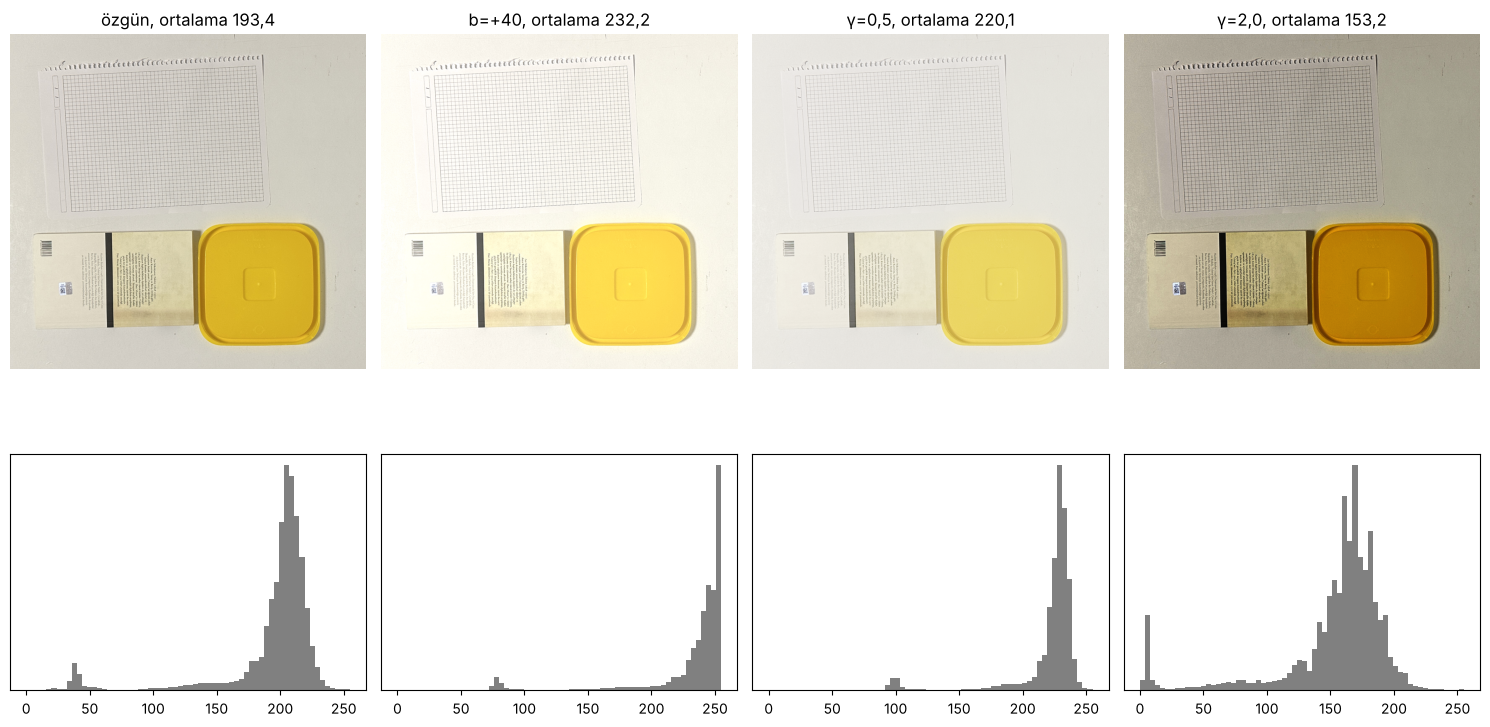

In [17]:
fig, ax = plt.subplots(2, 4, figsize=(15, 9), gridspec_kw={"height_ratios": [3, 1]})
goster = [("özgün", I.astype(np.float64))] + [(a, J) for a, J, _ in donusumler]
for j, (ad, J) in enumerate(goster):
    ax[0, j].imshow(J.astype(np.uint8)); ax[0, j].set_title(f"{ad}, ortalama {J.mean():.1f}".replace(".", ",")); ax[0, j].axis("off")
    ax[1, j].hist(J.ravel(), bins=64, range=(0, 255), color="gray"); ax[1, j].set_yticks([])
plt.tight_layout(); plt.savefig(f"{CIKTI}/04_parlaklik_gama.png", dpi=110); plt.show()

## Adım 7: Küçültmenin etkisi (Hedef 4)

Yazılı ve çizgili bölgeyi genişlik ve yükseklikte 1/4'e küçültüyorum (INTER_NEAREST ve INTER_AREA). Sonra sadece göstermek için iki sonucu en yakın komşuyla özgün boyuta büyütüyorum.

### Tahminim

Kitaptaki harfler 1/4 küçültmede birkaç piksele inip iki yöntemde de okunmaz olacak. En yakın komşu kareli kâğıttaki çizgilerin bir kısmını atlayıp düzensiz bir desen üretecek; alan ortalaması çizgileri silik griye çevirecek ama sahte desen üretmeyecek.

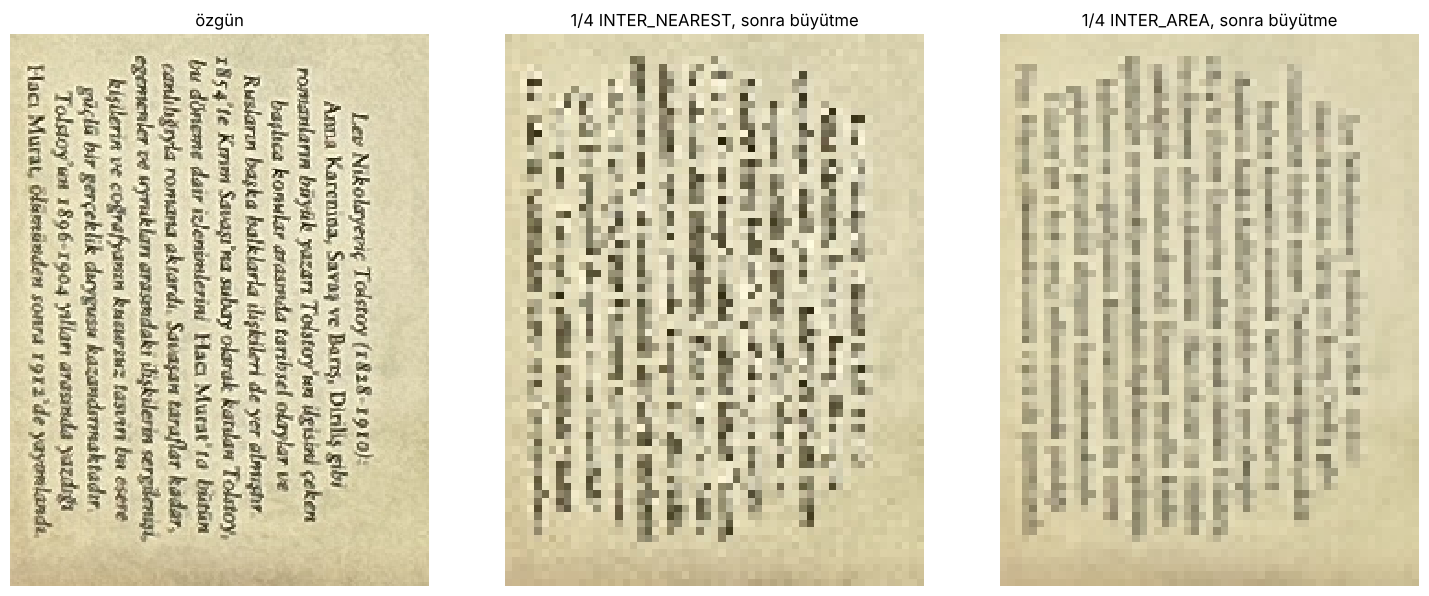

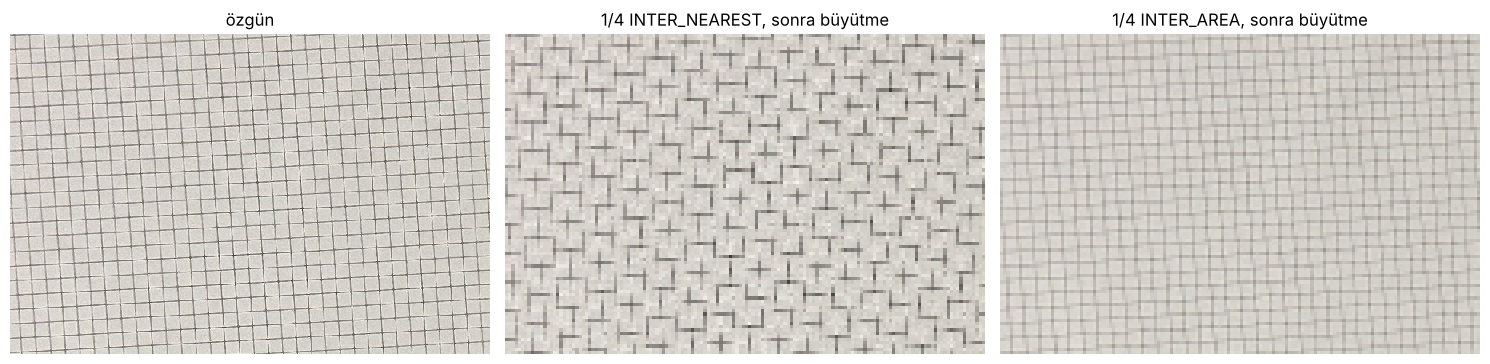

In [18]:
def kucult_buyut(kesit, yontem):
    h, w = kesit.shape[:2]
    k = cv2.resize(kesit, (w // OLCEK, h // OLCEK), interpolation=yontem)
    b = cv2.resize(k, (k.shape[1] * OLCEK, k.shape[0] * OLCEK), interpolation=cv2.INTER_NEAREST)
    return k, b

def psnr(a, b):
    a = a[:b.shape[0], :b.shape[1]].astype(np.float64); b = b.astype(np.float64)
    mse = ((a - b) ** 2).mean()
    return 10 * np.log10(255 ** 2 / mse)

kucultme_satir = []
for ad, (x1, y1, x2, y2) in [("yazı", YAZI_KESIT), ("kareli kâğıt", CIZGI_KESIT)]:
    kesit = RGB["normal"][y1:y2, x1:x2]
    kn, bn = kucult_buyut(kesit, cv2.INTER_NEAREST)
    ka, ba = kucult_buyut(kesit, cv2.INTER_AREA)
    fig, ax = plt.subplots(1, 3, figsize=(15, 6))
    for a, (t, im) in zip(ax, [("özgün", kesit), ("1/4 INTER_NEAREST, sonra büyütme", bn), ("1/4 INTER_AREA, sonra büyütme", ba)]):
        a.imshow(im, interpolation="nearest"); a.set_title(t); a.axis("off")
    plt.tight_layout(); plt.savefig(f"{CIKTI}/05_kucultme_{'yazi' if ad == 'yazı' else 'cizgi'}.png", dpi=110); plt.show()
    for yon, k, b in [("INTER_NEAREST", kn, bn), ("INTER_AREA", ka, ba)]:
        kucultme_satir.append({"bölge": ad, "yöntem": yon, "özgün boyut": f"{kesit.shape[1]}x{kesit.shape[0]}",
                               "küçük boyut": f"{k.shape[1]}x{k.shape[0]}",
                               "PSNR (dB)": round(psnr(kesit, b), 2),
                               "özgün std": round(float(kesit.std()), 1), "sonuç std": round(float(b.std()), 1)})

özgün          dikey çizgi sayısı:  33   kontrast (medyan - en koyu): 47.5
INTER_NEAREST  dikey çizgi sayısı:  14   kontrast (medyan - en koyu): 52.6
INTER_AREA     dikey çizgi sayısı:  23   kontrast (medyan - en koyu): 26.6


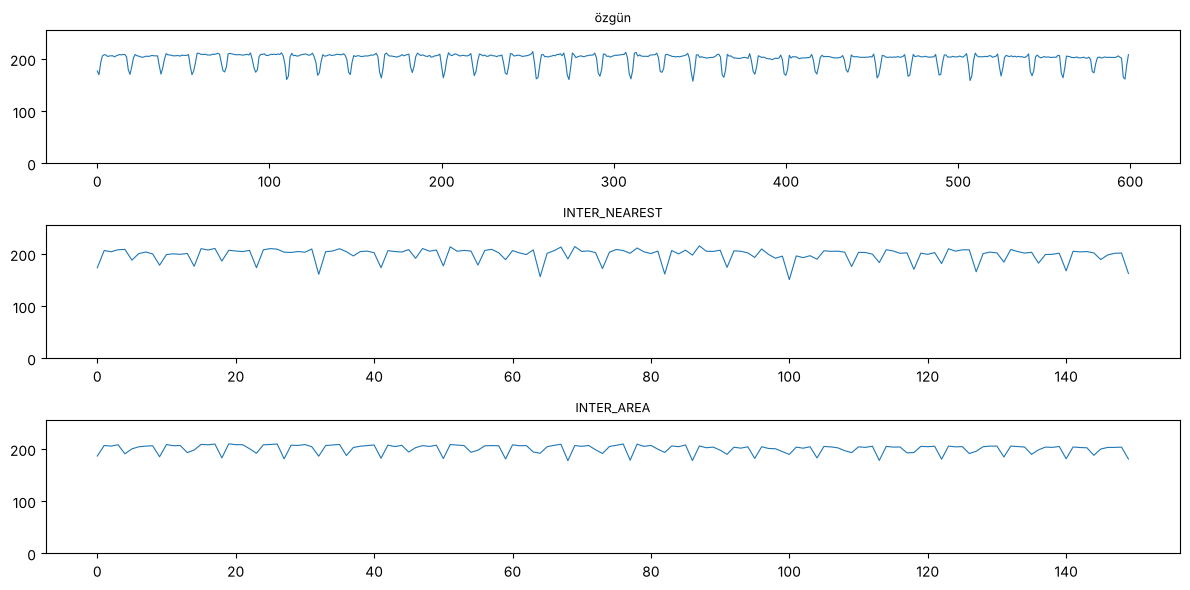

,bölge,yöntem,özgün boyut,küçük boyut,PSNR (dB),özgün std,sonuç std,dikey çizgi sayısı,çizgi kontrastı
0,yazı,INTER_NEAREST,228x300,57x75,14.50,46.5,45.6,NaN,NaN
1,yazı,INTER_AREA,228x300,57x75,17.36,46.5,31.2,NaN,NaN
2,kareli kâğıt,INTER_NEAREST,600x400,150x100,17.71,28.0,26.8,14.0,52.6
3,kareli kâğıt,INTER_AREA,600x400,150x100,20.59,28.0,14.8,23.0,26.6


In [19]:
# Çizgileri saymak: kesitin sütun ortalaması profilinde koyu çizgiler çukur olarak görünür.
def cizgi_say(gri_kesit, k=0.5):
    # kâğıt hafif eğik durduğu için sadece ortadaki ince bir şeridin sütun ortalamasını alıyorum
    h = gri_kesit.shape[0]; bant = max(h // 10, 4)
    p = gri_kesit[h // 2 - bant // 2: h // 2 + bant // 2].astype(np.float64).mean(0)
    esik = np.median(p) - k * (np.median(p) - p.min())
    koyu = p < esik
    baslangic = np.flatnonzero(koyu[1:] & ~koyu[:-1]) + 1
    kontrast = np.median(p) - p.min()
    return len(baslangic), round(kontrast, 1), p

x1, y1, x2, y2 = CIZGI_KESIT
gri = cv2.cvtColor(BGR["normal"][y1:y2, x1:x2], cv2.COLOR_BGR2GRAY)
profiller = {}
for yon, yontem in [("özgün", None), ("INTER_NEAREST", cv2.INTER_NEAREST), ("INTER_AREA", cv2.INTER_AREA)]:
    g = gri if yontem is None else cv2.resize(gri, (gri.shape[1] // OLCEK, gri.shape[0] // OLCEK), interpolation=yontem)
    n, kon, p = cizgi_say(g)
    profiller[yon] = p
    for s in kucultme_satir:
        if s["bölge"] == "kareli kâğıt" and s["yöntem"] == yon:
            s["dikey çizgi sayısı"] = n; s["çizgi kontrastı"] = kon
    print(f"{yon:14s} dikey çizgi sayısı: {n:3d}   kontrast (medyan - en koyu): {kon}")

fig, ax = plt.subplots(3, 1, figsize=(12, 6), sharex=False)
for a, (yon, p) in zip(ax, profiller.items()):
    a.plot(p, lw=0.8); a.set_title(yon, fontsize=9); a.set_ylim(0, 255)
plt.tight_layout(); plt.savefig(f"{CIKTI}/06_cizgi_profili.png", dpi=110); plt.show()

kucultme_tablo = pd.DataFrame(kucultme_satir)
kucultme_tablo.to_csv(f"{CIKTI}/adim7_kucultme.csv", index=False, encoding="utf-8-sig")
kucultme_tablo

In [20]:
# Sayım eşiğe ne kadar bağlı? eşik = medyan - k * (medyan - en koyu); yukarıda k = 0,5 kullandım.
k_satir = []
for k in [0.3, 0.5, 0.7]:
    satir = {"k": k}
    for yon, yontem in [("özgün", None), ("INTER_NEAREST", cv2.INTER_NEAREST), ("INTER_AREA", cv2.INTER_AREA)]:
        g = gri if yontem is None else cv2.resize(gri, (gri.shape[1] // OLCEK, gri.shape[0] // OLCEK), interpolation=yontem)
        satir[yon] = cizgi_say(g, k)[0]
    k_satir.append(satir)
k_tablo = pd.DataFrame(k_satir)
k_tablo.to_csv(f"{CIKTI}/adim7_esik_duyarlilik.csv", index=False, encoding="utf-8-sig")
k_tablo

,k,özgün,INTER_NEAREST,INTER_AREA
0,0.3,33,22,33
1,0.5,33,14,23
2,0.7,28,6,16


In [21]:
# Yazı satırlarının aralığı: kitapta satırlar fotoğrafta dikey duruyor, sütun profilinin baskın periyodunu FFT ile buluyorum.
x1, y1, x2, y2 = YAZI_KESIT
gy = cv2.cvtColor(BGR["normal"][y1:y2, x1:x2], cv2.COLOR_BGR2GRAY).astype(np.float64)
p = gy.mean(0) - gy.mean()
f = np.abs(np.fft.rfft(p)); f[:3] = 0
periyot = len(p) / np.argmax(f)
print(f"satır aralığı ≈ {periyot:.1f} px  ->  1/4 küçültmede ≈ {periyot / OLCEK:.1f} px")

satır aralığı ≈ 14.2 px  ->  1/4 küçültmede ≈ 3.6 px


## Rapor görselleri

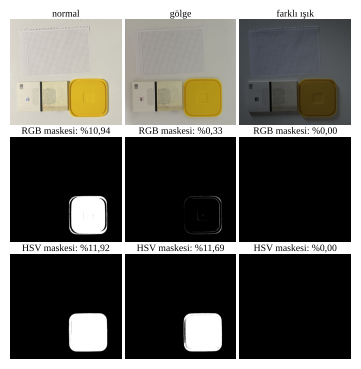

In [22]:
# Rapor IEEE biçiminde iki sütunlu; şekilleri tek sütun genişliğinde (yaklaşık 3,45 inç) çiziyorum ki yazılar küçülmesin.
plt.rcParams.update({"font.family": "serif", "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"], "font.size": 7})
fig, ax = plt.subplots(3, 3, figsize=(3.45, 3.55))
for j, k in enumerate(KOSULLAR):
    ax[0, j].imshow(RGB[k]); ax[0, j].set_title(k, fontsize=7, pad=2)
    for i, tur in enumerate(["RGB", "HSV"], start=1):
        m = MASKE[(k, tur)]
        ax[i, j].imshow(m, cmap="gray", vmin=0, vmax=255)
        ax[i, j].set_title(f"{tur} maskesi: %{100 * (m > 0).mean():.2f}".replace(".", ","), fontsize=7, pad=2)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(pad=0.2, h_pad=0.4, w_pad=0.3); plt.savefig(f"{CIKTI}/rapor_sekil1.png", dpi=300); plt.show()

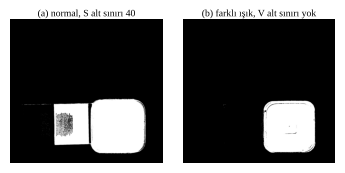

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(3.45, 1.55))
m = cv2.inRange(cv2.cvtColor(BGR["normal"], cv2.COLOR_BGR2HSV), GEVSEK_S_ALT, HSV_UST)
ax[0].imshow(m, cmap="gray"); ax[0].set_title("(a) normal, S alt sınırı 40", fontsize=7, pad=2)
m = cv2.inRange(cv2.cvtColor(BGR["farklı ışık"], cv2.COLOR_BGR2HSV), V_SIZ_ALT, HSV_UST)
ax[1].imshow(m, cmap="gray"); ax[1].set_title("(b) farklı ışık, V alt sınırı yok", fontsize=7, pad=2)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(pad=0.2, w_pad=0.4); plt.savefig(f"{CIKTI}/rapor_sekil2.png", dpi=300); plt.show()

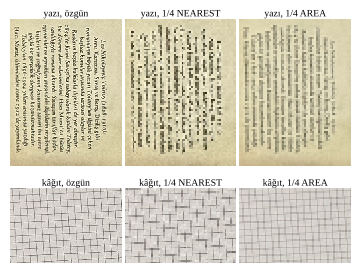

In [24]:
fig, ax = plt.subplots(2, 3, figsize=(3.45, 2.75), gridspec_kw={"height_ratios": [1.3, 0.67]})
for i, (ad, (x1, y1, x2, y2)) in enumerate([("yazı", YAZI_KESIT), ("kâğıt", (400, 300, 700, 500))]):
    kesit = RGB["normal"][y1:y2, x1:x2]
    _, bn = kucult_buyut(kesit, cv2.INTER_NEAREST)
    _, ba = kucult_buyut(kesit, cv2.INTER_AREA)
    for j, (t, im) in enumerate([("özgün", kesit), ("1/4 NEAREST", bn), ("1/4 AREA", ba)]):
        ax[i, j].imshow(im, interpolation="nearest"); ax[i, j].set_title(f"{ad}, {t}", fontsize=7, pad=2)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(pad=0.2, h_pad=0.4, w_pad=0.3); plt.savefig(f"{CIKTI}/rapor_sekil3.png", dpi=300); plt.show()
plt.rcParams.update(plt.rcParamsDefault); plt.rcParams.update({"figure.max_open_warning": 0})

## Sonuç tablosu

In [25]:
ozet = []
for _, r in maske_tablo.iterrows():
    ozet.append({"deney": "Adım 5 maske", "koşul": f'{r["koşul"]} / {r["renk uzayı"]}', "ölçüm": "alan oranı (%)", "değer": r["alan oranı (%)"]})
for _, r in donusum_tablo.iterrows():
    ozet.append({"deney": "Adım 6 dönüşüm", "koşul": r["işlem"], "ölçüm": "ortalama (tahmin / ölçüm)",
                 "değer": f'{"yok" if pd.isna(r["tahmini ortalama"]) else r["tahmini ortalama"]} / {r["ölçülen ortalama"]}'})
for _, r in kucultme_tablo.iterrows():
    ozet.append({"deney": "Adım 7 küçültme", "koşul": f'{r["bölge"]} / {r["yöntem"]}', "ölçüm": "PSNR (dB)", "değer": r["PSNR (dB)"]})
sonuc = pd.DataFrame(ozet)
sonuc.to_csv(f"{CIKTI}/sonuc_tablosu.csv", index=False, encoding="utf-8-sig")
sonuc

,deney,koşul,ölçüm,değer
0,Adım 5 maske,normal / RGB,alan oranı (%),10.94
1,Adım 5 maske,normal / HSV,alan oranı (%),11.92
2,Adım 5 maske,gölge / RGB,alan oranı (%),0.33
3,Adım 5 maske,gölge / HSV,alan oranı (%),11.69
4,Adım 5 maske,farklı ışık / RGB,alan oranı (%),0.0
5,Adım 5 maske,farklı ışık / HSV,alan oranı (%),0.0
6,Adım 6 dönüşüm,özgün,ortalama (tahmin / ölçüm),yok / 193.44
7,Adım 6 dönüşüm,b=+40,ortalama (tahmin / ölçüm),233.44 / 232.15
8,Adım 6 dönüşüm,γ=0.5,ortalama (tahmin / ölçüm),222.1 / 220.07
9,Adım 6 dönüşüm,γ=2.0,ortalama (tahmin / ölçüm),146.74 / 153.17
